## Import & Setup

In [2]:
import importlib.metadata as metadata
import subprocess
import sys

def installed_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

required = {
    "opencv-contrib-python-headless": "4.13.0.92",
    "pycolmap": "3.13.0",
}
# OpenCV's wheel variants share the cv2 namespace. Keep one variant.
other_opencv = [name for name in ["opencv-python", "opencv-python-headless",
                                "opencv-contrib-python"]
                if installed_version(name) is not None]
if other_opencv:
    subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-q", "-y",
                           *other_opencv])
if other_opencv or any(installed_version(k) != v for k, v in required.items()):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        *[f"{k}=={v}" for k, v in required.items()],
        "numpy>=2,<3", "scipy>=1.11", "matplotlib>=3.8", "pillow"])
print("Software installed.")

Software installed.


In [3]:
from pathlib import Path
import hashlib
import json
import shutil
import time
import urllib.request
import zipfile

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pycolmap
from scipy.optimize import least_squares
from IPython.display import display

np.set_printoptions(precision=4, suppress=True)
cv2.setRNGSeed(5561)
rng = np.random.default_rng(5561)
print("Python:", sys.version.split()[0])
print("OpenCV:", cv2.__version__)
print("PyCOLMAP:", pycolmap.__version__)
print("NumPy:", np.__version__)

Python: 3.11.17
OpenCV: 4.13.0
PyCOLMAP: 3.13.0
NumPy: 2.4.6


## 1. Gather Photographs

Displaying 12 images (images 20 to 31).
Selected pair for two-view reconstruction: ['image_27.jpg', 'image_29.jpg']


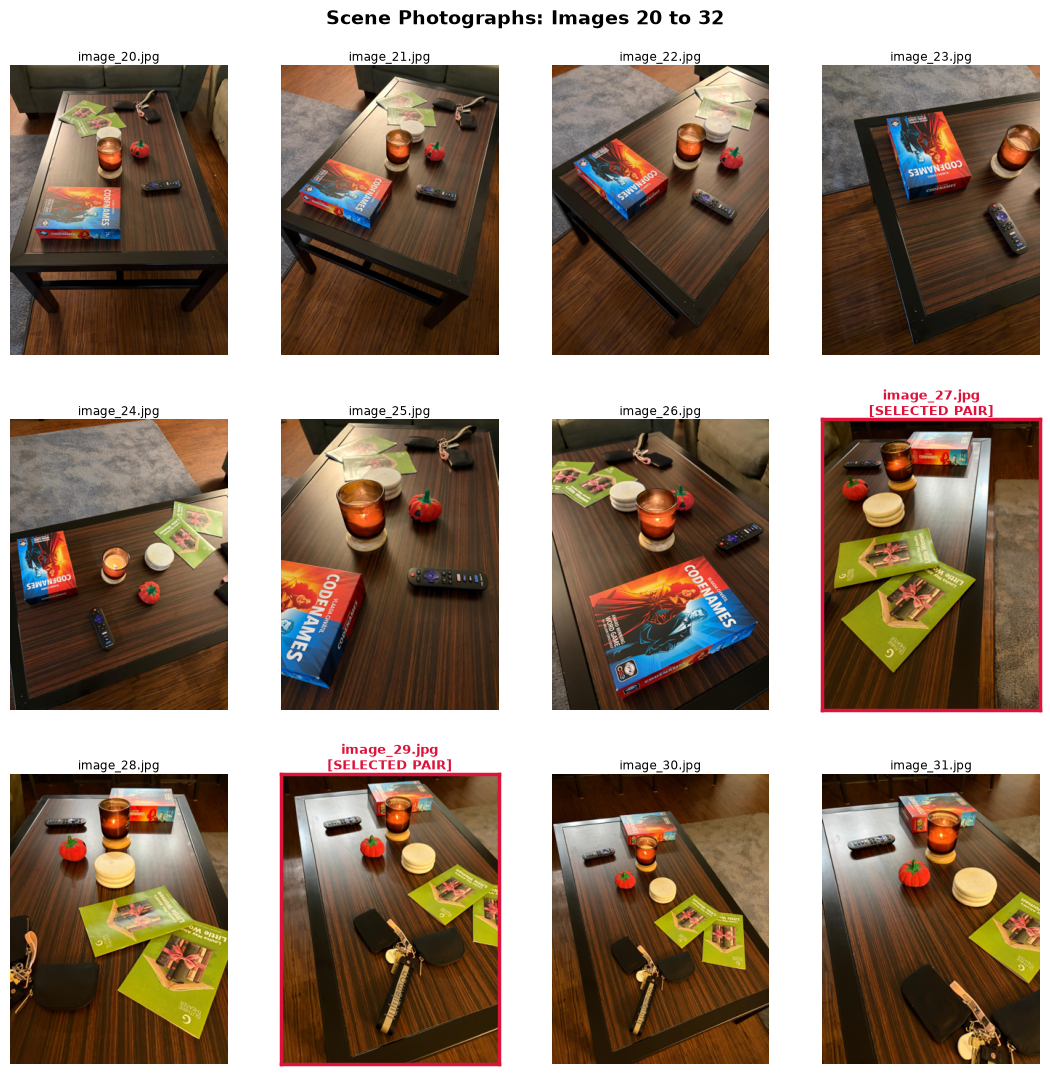

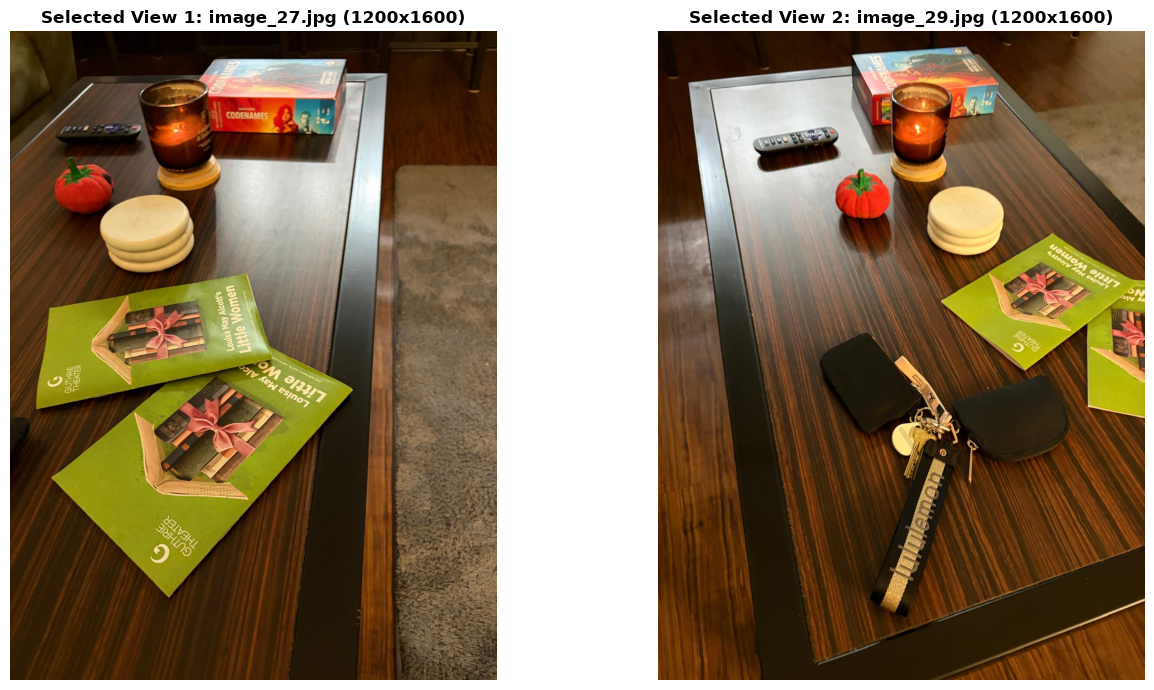

In [19]:
from PIL import Image

# 1. Setup paths and filter images 20 to 32 (inclusive)
img_dir = Path("Images")
all_images = sorted(img_dir.glob("*.jpg"))

photos = [cv2.imread(str(p)) for p in all_images]
scene_dir = img_dir
names = [p.name for p in all_images]
size = (photos[0].shape[1], photos[0].shape[0])  # OpenCV uses (width, height).
print("Image size (width, height):", size)

# Filter images 20 to 32
display_images = [
    p for p in all_images 
    if p.stem.startswith("image_") and 20 <= int(p.stem.split("_")[-1]) <= 31
]
pair_names = {"image_27.jpg", "image_29.jpg"}

print(f"Displaying {len(display_images)} images (images 20 to 31).")
print(f"Selected pair for two-view reconstruction: {sorted(pair_names)}")

# 2. Display filtered images with minimal gaps
cols = 4
rows = (len(display_images) + cols - 1) // cols

# 1) Match figsize to the portrait 3:4 aspect ratio (col_w / row_h ≈ 0.75)
col_w = 2.8
row_h = 3.7
fig, axes = plt.subplots(rows, cols, figsize=(cols * col_w, rows * row_h))

for i, ax in enumerate(axes.ravel()):
    if i < len(display_images):
        p = display_images[i]
        im = Image.open(p)
        im.thumbnail((300, 400))
        ax.imshow(im)
        
        # Highlight image 27 and image 29
        if p.name in pair_names:
            ax.set_title(f"{p.name}\n[SELECTED PAIR]", color="crimson", fontweight="bold", fontsize=9, pad=3)
            for spine in ax.spines.values():
                spine.set_edgecolor("crimson")
                spine.set_linewidth(2.5)
        else:
            ax.set_title(p.name, fontsize=8.5, pad=3)
            for spine in ax.spines.values():
                spine.set_visible(False)
    else:
        ax.axis("off")
        
    ax.set_xticks([])
    ax.set_yticks([])

# 2) Replace plt.tight_layout() with subplots_adjust for tight gaps
plt.subplots_adjust(
    left=0.02, right=0.98,
    top=0.92, bottom=0.02,
    wspace=0.03,  # Horizontal gap between images (smaller = tighter)
    hspace=0.22   # Vertical gap (leaves just enough room for the titles)
)

plt.suptitle("Scene Photographs: Images 20 to 32", fontsize=14, y=0.97, fontweight="bold")

# Save for report
figures_dir = Path("Report") / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "images_20_to_32_grid.png", dpi=200, bbox_inches="tight")
plt.show()

# -------------------------------------------------------------
# 3. High-resolution side-by-side view of the selected pair
# -------------------------------------------------------------
img27 = cv2.cvtColor(cv2.imread(str(img_dir / "image_27.jpg")), cv2.COLOR_BGR2RGB)
img29 = cv2.cvtColor(cv2.imread(str(img_dir / "image_29.jpg")), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(img27)
axes[0].set_title(f"Selected View 1: image_27.jpg ({img27.shape[1]}x{img27.shape[0]})", fontsize=12, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(img29)
axes[1].set_title(f"Selected View 2: image_29.jpg ({img29.shape[1]}x{img29.shape[0]})", fontsize=12, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.savefig(figures_dir / "representative_images.png", dpi=200, bbox_inches="tight")
plt.show()


## 2. Estimate Camera Parameters

In [20]:
db_path = "results/colmap.db"
img_dir = "Images"
output_dir = "results/colmap_sparse"
Path(output_dir).mkdir(parents=True, exist_ok=True)

# Reuse existing reconstruction if available to avoid re-running
if Path("results/colmap_sparse/0/cameras.bin").exists():
    rec = pycolmap.Reconstruction("results/colmap_sparse/0")
else:
    # 1. Extract features
    pycolmap.extract_features(db_path, img_dir, camera_model="SIMPLE_RADIAL")
    # 2. Match features across views
    pycolmap.match_exhaustive(db_path)
    # 3. Incremental reconstruction
    reconstructions = pycolmap.incremental_mapping(db_path, img_dir, output_dir)
    rec = reconstructions[0]  # The main reconstructed model


In [21]:
# Grab the camera (since all photos were taken with the same phone camera)
camera = list(rec.cameras.values())[0]

print("Model:", camera.model.name)
print("Width x Height:", camera.width, camera.height)
print("Fitted parameters:", camera.params)

Model: SIMPLE_RADIAL
Width x Height: 1200 1600
Fitted parameters: [1232.3286  600.      800.        0.0089]


In [22]:
import numpy as np

def simple_radial_to_opencv(camera):
    if camera.model.name != "SIMPLE_RADIAL":
        raise ValueError(f"Expected SIMPLE_RADIAL, got {camera.model.name}")
    
    focal, cx, cy, radial = camera.params
    
    # Subtract 0.5 for OpenCV coordinate convention
    K_cv = np.array([
        [focal,   0.0, cx - 0.5],
        [  0.0, focal, cy - 0.5],
        [  0.0,   0.0,      1.0]
    ])
    
    # OpenCV distortion: (k1, k2, p1, p2, k3)
    dist_cv = np.array([radial, 0.0, 0.0, 0.0, 0.0])
    
    return K_cv, dist_cv

K_colmap, dist_colmap = simple_radial_to_opencv(camera)

print("Intrinsic Matrix K:\n", K_colmap)
print("Distortion coefficients:\n", dist_colmap)
# Alias K and dist for downstream cells
K, dist = K_colmap, dist_colmap


Intrinsic Matrix K:
 [[1232.3286    0.      599.5   ]
 [   0.     1232.3286  799.5   ]
 [   0.        0.        1.    ]]
Distortion coefficients:
 [0.0089 0.     0.     0.     0.    ]


### Find SIFT Matches

In [23]:
# image_27.jpg and image_29.jpg correspond to our selected pair
idx1 = [i for i, p in enumerate(all_images) if p.name == "image_27.jpg"][0]
idx2 = [i for i, p in enumerate(all_images) if p.name == "image_29.jpg"][0]
photo1 = photos[idx1]
photo2 = photos[idx2]

gray1 = cv2.cvtColor(photo1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(photo2, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create(nfeatures=8000)
k1, d1 = sift.detectAndCompute(gray1, None)
k2, d2 = sift.detectAndCompute(gray2, None)
neighbors = cv2.BFMatcher().knnMatch(d1, d2, k=2)
ratio = 0.75
matches = [m for pair in neighbors if len(pair) == 2
           for m, n in [pair] if m.distance < ratio * n.distance]
p1 = np.float64([k1[m.queryIdx].pt for m in matches])
p2 = np.float64([k2[m.trainIdx].pt for m in matches])
assert len(matches) >= 5, "Too few tentative matches to estimate E."
print("Keypoints in photo 1 (image_27):", len(k1))
print("Keypoints in photo 2 (image_29):", len(k2))
print("Matches after the ratio test:", len(matches))
print("p1 shape:", p1.shape, "  p2 shape:", p2.shape)
print("First photo-1 pixel:", p1[0])
print("Its proposed photo-2 match:", p2[0])


Keypoints in photo 1 (image_27): 5904
Keypoints in photo 2 (image_29): 4058
Matches after the ratio test: 143
p1 shape: (143, 2)   p2 shape: (143, 2)
First photo-1 pixel: [ 68.9585 261.5845]
Its proposed photo-2 match: [ 727.6582 1445.0016]


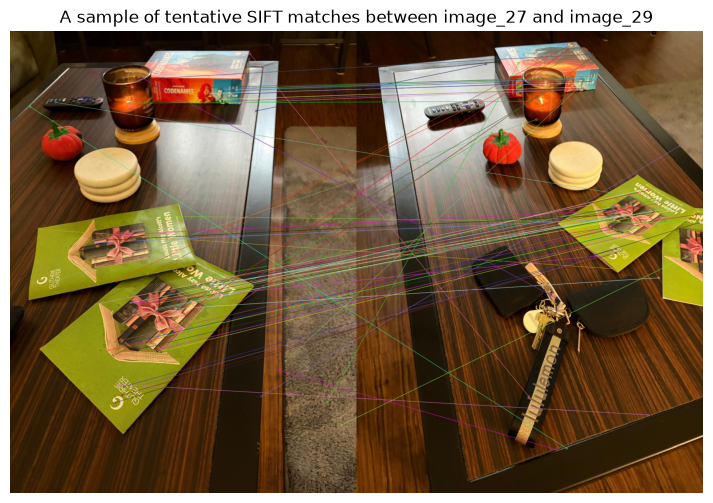

In [24]:
shown_ids = rng.choice(len(matches), size=min(70, len(matches)), replace=False)
match_picture = cv2.drawMatches(photo1, k1, photo2, k2,
    [matches[i] for i in shown_ids], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(15, 6))
plt.imshow(cv2.cvtColor(match_picture, cv2.COLOR_BGR2RGB))
plt.title("A sample of tentative SIFT matches between image_27 and image_29")
plt.axis("off")
plt.savefig(figures_dir / "sift_matches_27_29.png", dpi=200, bbox_inches="tight")
plt.show()


### Remove Distortion and Fit E

In [25]:
q1 = cv2.undistortPoints(p1[:, None], K, dist, P=K).reshape(-1, 2)
q2 = cv2.undistortPoints(p2[:, None], K, dist, P=K).reshape(-1, 2)
example_row = int(np.argmax(np.linalg.norm(q1 - p1, axis=1)))
print("Photo-1 row:", example_row)
print("Before undistortion (px):", p1[example_row])
print("After undistortion (px):", q1[example_row])
print("Shift (px):", np.linalg.norm(q1[example_row] - p1[example_row]))

Photo-1 row: 140
Before undistortion (px): [1081.6169 1459.9205]
After undistortion (px): [1079.7576 1457.3736]
Shift (px): 3.1534124758521798


In [26]:
cv2.setRNGSeed(5561)
E, e_mask = cv2.findEssentialMat(q1, q2, K, method=cv2.RANSAC,
    prob=0.999, threshold=1.0)
if E is None or E.shape != (3, 3) or e_mask is None:
    raise RuntimeError("No single E was found. Inspect the photos and tentative matches.")
e_keep = e_mask.ravel() != 0
print("E:\n", E)
print("Singular values of E:", np.linalg.svd(E, compute_uv=False))
print("E inliers:", int(e_keep.sum()), "of", len(q1))

E:
 [[-0.082  -0.4689 -0.2256]
 [ 0.4617 -0.1113 -0.4602]
 [ 0.333   0.4171 -0.019 ]]
Singular values of E: [0.7071 0.7071 0.    ]
E inliers: 51 of 143


### Recover R and t

In [27]:
# Recover relative pose (R, t) from Essential matrix
n_pose, R, t, pose_mask = cv2.recoverPose(E, q1, q2, K, mask=e_mask.copy())
pose_keep = (pose_mask.ravel() != 0)

x1 = q1[pose_keep]
x2 = q2[pose_keep]

# Camera projection matrices: P1 = K[I | 0], P2 = K[R | t]
P1 = K @ np.column_stack([np.eye(3), np.zeros(3)])
P2 = K @ np.column_stack([R, t])

print("Pose-valid inlier matches:", n_pose)
print("Rotation Matrix R (Cam 1 -> Cam 2):\n", R)
print("Translation Vector t (unit length):\n", t.ravel())
print("P1 shape:", P1.shape, " | P2 shape:", P2.shape)
print("Retained correspondences for triangulation:", len(x1))

Pose-valid inlier matches: 50
Rotation Matrix R (Cam 1 -> Cam 2):
 [[ 0.9828 -0.1832  0.0233]
 [ 0.1842  0.9815 -0.0527]
 [-0.0133  0.0561  0.9983]]
Translation Vector t (unit length):
 [ 0.6672 -0.3541  0.6554]
P1 shape: (3, 4)  | P2 shape: (3, 4)
Retained correspondences for triangulation: 50


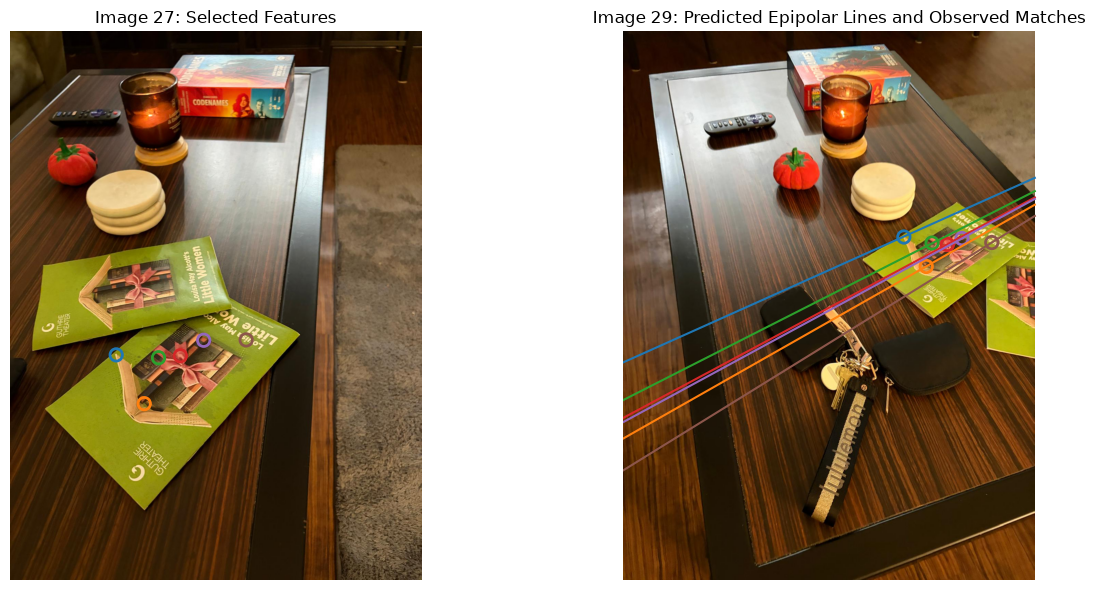

In [28]:
# Epipolar line verification
K_inv = np.linalg.inv(K)
F_from_E = K_inv.T @ E @ K_inv

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(photo1, cv2.COLOR_BGR2RGB))
axes[1].imshow(cv2.cvtColor(photo2, cv2.COLOR_BGR2RGB))

sample_rows = np.flatnonzero(pose_keep)[::max(1, int(n_pose) // 6)][:6]
colors = plt.cm.tab10.colors

for idx, c in zip(sample_rows, colors):
    axes[0].scatter(q1[idx, 0], q1[idx, 1], s=80, facecolors="none", edgecolors=[c], linewidths=2)
    
    # Epipolar line in image 2: l = F * x1
    line = F_from_E @ np.r_[q1[idx], 1.0]
    a, b, c_val = line
    x_vals = np.array([0, photo2.shape[1]])
    y_vals = -(a * x_vals + c_val) / b
    axes[1].plot(x_vals, y_vals, color=c, linewidth=1.5)
    axes[1].scatter(q2[idx, 0], q2[idx, 1], s=80, facecolors="none", edgecolors=[c], linewidths=2)

axes[0].set_title("Image 27: Selected Features")
axes[0].axis("off")
axes[1].set_title("Image 29: Predicted Epipolar Lines and Observed Matches")
axes[1].axis("off")
plt.tight_layout()
plt.savefig(figures_dir / "epipolar_lines_27_29.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Two-Image 3D Reconstruction with SVD

In [29]:
def triangulate(P1, P2, x1, x2):
    A = np.vstack([x1[0] * P1[2] - P1[0],
                   x1[1] * P1[2] - P1[1],
                   x2[0] * P2[2] - P2[0],
                   x2[1] * P2[2] - P2[1]])
    _, _, Vt = np.linalg.svd(A)
    Xh = Vt[-1]
    if abs(Xh[3]) < 1e-12:
        return np.full(3, np.nan)
    return Xh[:3] / Xh[3]

def project(P, points):
    homogeneous = np.column_stack([points, np.ones(len(points))])
    image_h = homogeneous @ P.T
    pixels = np.full((len(points), 2), np.nan)
    good = np.isfinite(image_h).all(axis=1) & (np.abs(image_h[:, 2]) > 1e-12)
    pixels[good] = image_h[good, :2] / image_h[good, 2:3]
    return pixels

In [31]:
K_test = np.array([[800., 0, 500], [0, 800., 375], [0, 0, 1.]])
R_test = cv2.Rodrigues(np.array([0.02, -0.08, 0.01]))[0]
t_test = np.array([-0.5, 0.02, 0.03])
P_test1 = K_test @ np.column_stack([np.eye(3), np.zeros(3)])
P_test2 = K_test @ np.column_stack([R_test, t_test])
X_true = np.array([[-0.4, -0.2, 3.], [0.1, 0.3, 4.],
                   [0.8, -0.1, 5.], [-0.2, 0.5, 6.]])
assert np.all(X_true[:, 2] > 0)
assert np.all((X_true @ R_test.T + t_test)[:, 2] > 0)
test_x1, test_x2 = project(P_test1, X_true), project(P_test2, X_true)
X_test = np.array([triangulate(P_test1, P_test2, a, b)
                   for a, b in zip(test_x1, test_x2)])
synthetic_3d_error = np.linalg.norm(X_test - X_true, axis=1).max()
synthetic_pixel_error = max(
    np.linalg.norm(project(P_test1, X_test) - test_x1, axis=1).max(),
    np.linalg.norm(project(P_test2, X_test) - test_x2, axis=1).max())
print("Maximum synthetic 3D error:", synthetic_3d_error)
print("Maximum synthetic reprojection error (px):", synthetic_pixel_error)
assert synthetic_3d_error < 1e-10 and synthetic_pixel_error < 1e-9

# Scaling the scene and baseline together preserves both images.
P_scaled = K_test @ np.column_stack([R_test, 7 * t_test])
assert np.allclose(project(P_scaled, 7 * X_true), test_x2)

Maximum synthetic 3D error: 1.0002487165449584e-14
Maximum synthetic reprojection error (px): 1.797546735911271e-13


In [35]:
X = np.array([triangulate(P1, P2, a, b) for a, b in zip(x1, x2)])
finite = np.isfinite(X).all(axis=1)
X_camera2 = X @ R.T + t.ravel()
front = finite & (X[:, 2] > 0) & (X_camera2[:, 2] > 0)
pred1, pred2 = project(P1, X), project(P2, X)
e1 = np.linalg.norm(pred1 - x1, axis=1)
e2 = np.linalg.norm(pred2 - x2, axis=1)
valid = front & (e1 < 3.0) & (e2 < 3.0)
assert valid.any(), "No points passed the depth and reprojection checks."

print("Ratio-test matches:", len(matches))
print("E inliers:", int(e_keep.sum()))
print("Pose-valid matches:", int(pose_keep.sum()))
print("Finite 3D points:", int(finite.sum()))
print("Positive depth in both cameras:", int(front.sum()))
print("Final valid points:", int(valid.sum()))
print("Mean reprojection error, photo 1 (px):", e1[valid].mean())
print("Mean reprojection error, photo 2 (px):", e2[valid].mean())

Ratio-test matches: 143
E inliers: 51
Pose-valid matches: 50
Finite 3D points: 50
Positive depth in both cameras: 50
Final valid points: 50
Mean reprojection error, photo 1 (px): 0.333005382148386
Mean reprojection error, photo 2 (px): 0.22156424314378703


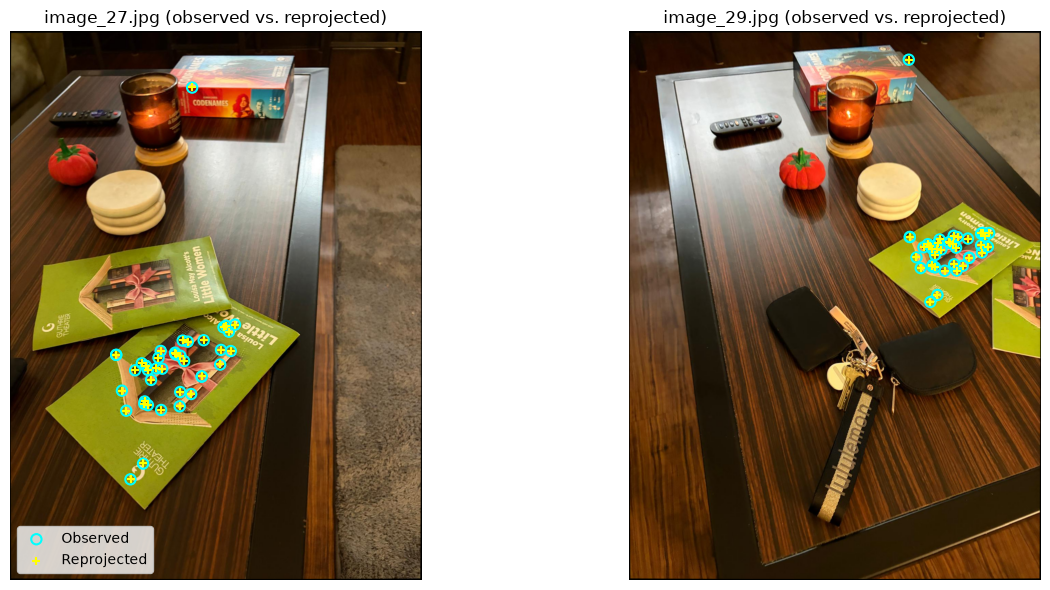

In [37]:
# Undistort both photographs using your fitted K and dist
undistorted_photos = [
    cv2.undistort(photo1, K, dist, None, K),
    cv2.undistort(photo2, K, dist, None, K)
]

overlay_ids = np.flatnonzero(valid)[::max(1, int(valid.sum()) // 40)][:40]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, image, observed, predicted, title in zip(axes, undistorted_photos,
        [x1, x2], [pred1, pred2], ["image_27.jpg", "image_29.jpg"]):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.scatter(*observed[overlay_ids].T, s=55, facecolors="none",
               edgecolors="cyan", label="Observed", linewidths=1.5)
    ax.scatter(*predicted[overlay_ids].T, s=40, c="yellow", marker="+",
               label="Reprojected", linewidths=1.5)
    ax.set_title(f"{title} (observed vs. reprojected)")
    ax.axis("off")

axes[0].legend(loc="lower left")
plt.tight_layout()

# Save figure for Section 3 of your report
figures_dir = Path("Report") / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "reprojection_panel.png", dpi=200, bbox_inches="tight")
plt.show()

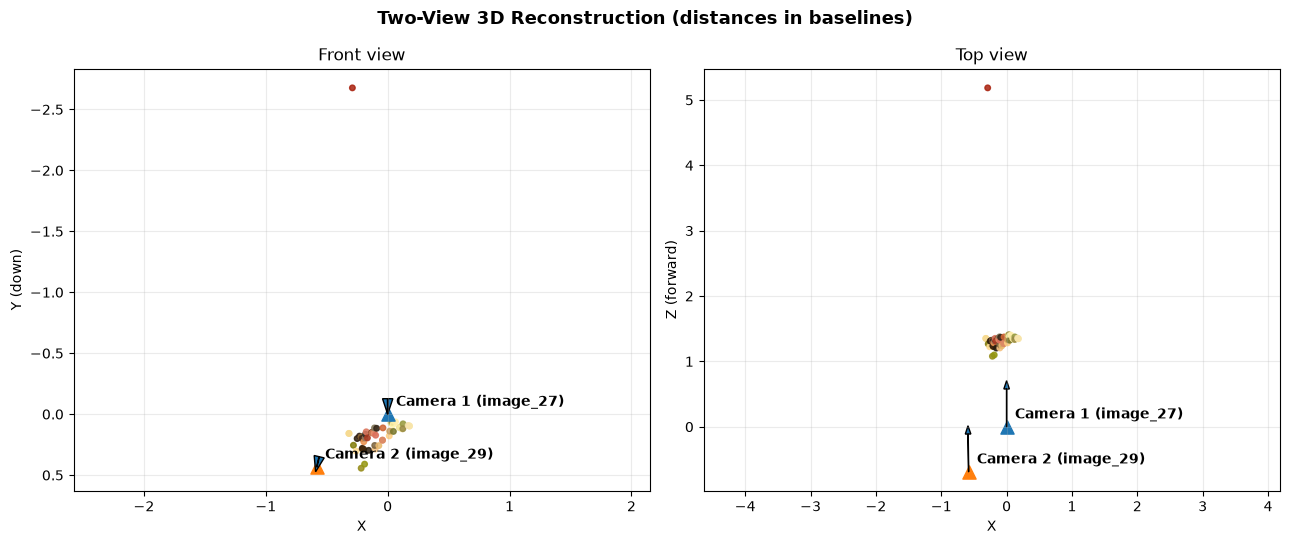

In [38]:
def plot_points_and_cameras(points, colors, poses, labels, title):
    centers = np.array([-rot.T @ trans.reshape(3) for rot, trans in poses])
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, vertical, ylabel, view in [(axes[0], 1, "Y (down)", "Front view"),
                                     (axes[1], 2, "Z (forward)", "Top view")]:
        ax.scatter(points[:, 0], points[:, vertical], c=colors, s=12)
        extent = np.ptp(np.vstack([points, centers]), axis=0).max()
        arrow_length = 0.12 * max(extent, 1e-6)
        for (rot, trans), center, label in zip(poses, centers, labels):
            forward = rot.T @ np.array([0., 0., 1.])
            ax.scatter(center[0], center[vertical], marker="^", s=80)
            ax.annotate(label, center[[0, vertical]], xytext=(5, 5),
                        textcoords="offset points")
            ax.arrow(center[0], center[vertical], arrow_length * forward[0],
                     arrow_length * forward[vertical], width=0.005 * arrow_length,
                     head_width=0.12 * arrow_length, length_includes_head=True)
        ax.set(xlabel="X", ylabel=ylabel, title=view)
        ax.set_aspect("equal", adjustable="datalim")
        ax.grid(alpha=0.25)
    axes[0].invert_yaxis()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

raw1_pose = p1[pose_keep]
color_pixels = np.rint(raw1_pose[valid]).astype(int)
color_pixels[:, 0] = np.clip(color_pixels[:, 0], 0, size[0] - 1)
color_pixels[:, 1] = np.clip(color_pixels[:, 1], 0, size[1] - 1)
rgb1 = cv2.cvtColor(photos[idx1], cv2.COLOR_BGR2RGB)
point_colors = rgb1[color_pixels[:, 1], color_pixels[:, 0]] / 255.0
pair_poses = [(np.eye(3), np.zeros(3)), (R, t.ravel())]
plot_points_and_cameras(X[valid], point_colors, pair_poses,
                       ["Camera 1", "Camera 2"], "Two-view: distances in baselines")


## 4. Multi-Image Reconstruction with COLMAP

In [52]:
import tempfile

# Start a new run directory each time this cell is run.
colmap_run = Path(tempfile.mkdtemp(prefix="colmap_scene_", dir=".")).resolve()
database_path = colmap_run / "database.db"
sparse_dir = colmap_run / "sparse"
sparse_dir.mkdir()
scene_dir = Path("Images")
f_initial = K[0, 0]  # Initial focal length estimate from Section 2
reader = pycolmap.ImageReaderOptions(
    camera_params=f"{f_initial},{size[0]/2},{size[1]/2},0")
extraction = pycolmap.FeatureExtractionOptions(
    num_threads=4, use_gpu=False, max_image_size=1000)
matching = pycolmap.FeatureMatchingOptions(num_threads=4, use_gpu=False)
mapping = pycolmap.IncrementalPipelineOptions(
    num_threads=4, random_seed=5561, min_model_size=3)

started = time.perf_counter()
# Reuse results/colmap_sparse/0 if already computed, else run incremental reconstruction
if Path("results/colmap_sparse/0").exists():
    rec = pycolmap.Reconstruction("results/colmap_sparse/0")
    models = {0: rec}
    print("Loaded existing reconstruction from results/colmap_sparse/0")
else:
    pycolmap.extract_features(str(database_path), str(scene_dir.resolve()),
        camera_mode=pycolmap.CameraMode.SINGLE, camera_model="SIMPLE_RADIAL",
        reader_options=reader, extraction_options=extraction, device=pycolmap.Device.cpu)
    pycolmap.match_exhaustive(str(database_path), matching_options=matching,
                            device=pycolmap.Device.cpu)
    models = pycolmap.incremental_mapping(str(database_path), str(scene_dir.resolve()),
                                        str(sparse_dir), options=mapping)
    if not models:
        raise RuntimeError("COLMAP did not reconstruct a model. Inspect its log and the photo overlap.")
    print("COLMAP elapsed time (s):", round(time.perf_counter() - started, 2))
print("Models reconstructed:", len(models))
for model_id, model in models.items():
    print(f"Model {model_id}: {model.num_reg_images()} images, {model.num_points3D()} points")
rec = max(models.values(), key=lambda model: (model.num_reg_images(), model.num_points3D()))


Loaded existing reconstruction from results/colmap_sparse/0
Models reconstructed: 1
Model 0: 38 images, 15091 points


In [53]:
registered_ids = rec.reg_image_ids()
registered_names = sorted(rec.images[i].name for i in registered_ids)
unregistered_names = sorted(set(names) - set(registered_names))
print("Registered photos:", registered_names)
print("Unregistered photos:", unregistered_names)
print("Registered / input:", rec.num_reg_images(), "/", len(names))
print("Sparse points:", rec.num_points3D())
print("Mean reprojection error reported by COLMAP (px):",
      rec.compute_mean_reprojection_error())
for camera_id, camera in rec.cameras.items():
    print("Camera ID:", camera_id)
    print("Model:", camera.model.name)
    print("Image size:", camera.width, camera.height)
    print("Parameters [f, cx, cy, k]:", camera.params)
print(rec.summary())


Registered photos: ['image_01.jpg', 'image_02.jpg', 'image_03.jpg', 'image_04.jpg', 'image_05.jpg', 'image_06.jpg', 'image_09.jpg', 'image_10.jpg', 'image_11.jpg', 'image_12.jpg', 'image_13.jpg', 'image_14.jpg', 'image_15.jpg', 'image_16.jpg', 'image_17.jpg', 'image_18.jpg', 'image_19.jpg', 'image_20.jpg', 'image_21.jpg', 'image_22.jpg', 'image_23.jpg', 'image_24.jpg', 'image_25.jpg', 'image_26.jpg', 'image_27.jpg', 'image_28.jpg', 'image_29.jpg', 'image_30.jpg', 'image_31.jpg', 'image_32.jpg', 'image_33.jpg', 'image_34.jpg', 'image_35.jpg', 'image_36.jpg', 'image_37.jpg', 'image_38.jpg', 'image_39.jpg', 'image_40.jpg']
Unregistered photos: []
Registered / input: 38 / 38
Sparse points: 15091
Mean reprojection error reported by COLMAP (px): 0.7951080352358864
Camera ID: 1
Model: SIMPLE_RADIAL
Image size: 1200 1600
Parameters [f, cx, cy, k]: [1232.376   600.      800.        0.0088]
Camera ID: 2
Model: SIMPLE_RADIAL
Image size: 1200 1600
Parameters [f, cx, cy, k]: [1231.1802  600.      8

### Inspect the cameras and points

In [ ]:
registered = {rec.images[i].name: rec.images[i] for i in registered_ids}
colmap_poses, colmap_labels = [], []
for name in names:
    if name not in registered:
        continue
    pose = registered[name].cam_from_world()
    colmap_poses.append((pose.rotation.matrix(), pose.translation.copy()))
    colmap_labels.append(f"{names.index(name) + 1}")
    print(name)
    print("  world-to-camera [R | t]:\n", pose.matrix())
    print("  camera center:", -pose.rotation.matrix().T @ pose.translation)

colmap_points = np.array([point.xyz for point in rec.points3D.values()])
colmap_colors = np.array([point.color for point in rec.points3D.values()]) / 255.0
plot_points_and_cameras(colmap_points, colmap_colors, colmap_poses, colmap_labels,
                       "COLMAP: arbitrary world coordinates")


image_01.jpg
  world-to-camera [R | t]:
 [[-0.5346 -0.8442  0.0377 -0.6045]
 [ 0.6988 -0.4166  0.5815 -3.6019]
 [-0.4752  0.3372  0.8127  2.9009]]
  camera center: [ 3.5724 -2.989  -0.2404]
image_02.jpg
  world-to-camera [R | t]:
 [[-0.6384 -0.7692 -0.0263 -0.262 ]
 [ 0.6242 -0.5375  0.567  -3.7249]
 [-0.4503  0.3455  0.8233  2.8508]]
  camera center: [ 3.4417 -3.1885 -0.242 ]
image_03.jpg
  world-to-camera [R | t]:
 [[-0.9594 -0.2758 -0.0593  0.1782]
 [ 0.201  -0.8159  0.5422 -3.8024]
 [-0.1979  0.5082  0.8382  2.5695]]
  camera center: [ 1.4439 -4.359  -0.0815]
image_04.jpg
  world-to-camera [R | t]:
 [[-0.987   0.1305 -0.0934  0.3298]
 [-0.1602 -0.8377  0.5221 -3.6508]
 [-0.0101  0.5303  0.8477  2.4112]]
  camera center: [-0.235  -4.38   -0.1071]
image_05.jpg
  world-to-camera [R | t]:
 [[-0.868   0.4836 -0.1128  0.7316]
 [-0.4595 -0.6961  0.5516 -3.8187]
 [ 0.1882  0.5306  0.8264  2.8412]]
  camera center: [-1.6543 -4.5197 -0.1592]
image_06.jpg
  world-to-camera [R | t]:
 [[-0.5283

### Triangulate using COLMAP's world poses

We can also triangulate the pair matches using the two poses directly from COLMAP. In that case, both projection matrices use COLMAP's common world frame.

In [55]:
pair_names = ["image_27.jpg", "image_29.jpg"]
pose1_world = registered[pair_names[0]].cam_from_world()
pose2_world = registered[pair_names[1]].cam_from_world()
P1_world = K @ pose1_world.matrix()
P2_world = K @ pose2_world.matrix()
# x1 and x2 are undistorted OpenCV pixels at the same image size.
X_world_pair = np.array([triangulate(P1_world, P2_world, a, b)
                         for a, b in zip(x1, x2)]).reshape(-1, 3)
world_e1 = np.linalg.norm(project(P1_world, X_world_pair) - x1, axis=1)
world_e2 = np.linalg.norm(project(P2_world, X_world_pair) - x2, axis=1)
depth1_world = (X_world_pair @ pose1_world.rotation.matrix().T + pose1_world.translation)[:, 2]
depth2_world = (X_world_pair @ pose2_world.rotation.matrix().T + pose2_world.translation)[:, 2]
world_valid = (np.isfinite(X_world_pair).all(axis=1) & (depth1_world > 0)
               & (depth2_world > 0) & (world_e1 < 3) & (world_e2 < 3))
print("Valid points triangulated in COLMAP's world frame:", int(world_valid.sum()))
if world_valid.any():
    print("Mean reprojection errors (px):", world_e1[world_valid].mean(), world_e2[world_valid].mean())


Valid points triangulated in COLMAP's world frame: 0


### Refine the triangulated points

In [56]:
valid_ids = np.flatnonzero(valid)
X_refined = X[valid].copy()
for row, point_id in enumerate(valid_ids):
    def residual(xyz):
        one_point = xyz.reshape(1, 3)
        return np.r_[project(P1, one_point)[0] - x1[point_id],
                     project(P2, one_point)[0] - x2[point_id]]
    result = least_squares(residual, X[point_id], method="lm", max_nfev=100)
    if result.success and np.isfinite(result.x).all():
        X_refined[row] = result.x

refined_e1 = np.linalg.norm(project(P1, X_refined) - x1[valid], axis=1)
refined_e2 = np.linalg.norm(project(P2, X_refined) - x2[valid], axis=1)
print("Mean error before, photos 1 and 2 (px):", e1[valid].mean(), e2[valid].mean())
print("Mean error after, photos 1 and 2 (px):", refined_e1.mean(), refined_e2.mean())
before_rms = np.sqrt(np.mean(np.r_[e1[valid] ** 2, e2[valid] ** 2]))
after_rms = np.sqrt(np.mean(np.r_[refined_e1 ** 2, refined_e2 ** 2]))
print("Joint reprojection RMS before / after (px):", before_rms, after_rms)
assert after_rms <= before_rms + 1e-10
print("Median 3D change (baselines):", np.median(np.linalg.norm(X_refined - X[valid], axis=1)))
print("Refined points in front of both cameras:", int(((X_refined[:, 2] > 0)
    & ((X_refined @ R.T + t.ravel())[:, 2] > 0)).sum()))


Mean error before, photos 1 and 2 (px): 0.333005382148386 0.22156424314378703
Mean error after, photos 1 and 2 (px): 0.20399418523199372 0.3066706857975837
Joint reprojection RMS before / after (px): 0.3680821016113732 0.33856848982467885
Median 3D change (baselines): 0.00012294601291344096
Refined points in front of both cameras: 50


### Save the results

In [57]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
np.savez_compressed(results_dir / "pair_reconstruction.npz",
    p1=p1, p2=p2, q1=q1, q2=q2, e_mask=e_mask, pose_keep=pose_keep,
    x1=x1, x2=x2, X=X, valid=valid, point_colors=point_colors,
    K=K, dist=dist, E=E, R=R, t=t, P1=P1, P2=P2,
    X_refined=X_refined)
print("Saved pair_reconstruction.npz to results/")


Saved pair_reconstruction.npz to results/
